<a href="https://colab.research.google.com/github/caiyunkai404602-jpg/DSAA2011-TaskA-RainAustralia/blob/main/Task4_partA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
# Task 4: Prediction — Training and Testing (Part A: Data Splitting, Linear Models & Decision Boundary)

##
## Objective This task establishes the supervised classification baseline for predicting `RainTomorrow`.
##In Part A, we partition the preprocessed dataset into training (70%) and testing (30%) sets, train two linear model classes covered in lectures (**Logistic Regression** and **Ridge Linear Classifier**), evaluate their performance individually on the **training set, testing set, and entire dataset**, and visualize the **2D decision boundaries**.

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# 1. Load preprocessed data from Task 1
X_PATH = "data/X_scaled_cleaned.csv"  # 若文件在同级目录，可改为 "X_scaled_cleaned.csv"
Y_PATH = "data/y_cleaned.csv"

X = pd.read_csv(X_PATH)
y = pd.read_csv(Y_PATH).iloc[:, 0]

# 2. Split dataset into 70% training set and 30% testing set (Deliverable 1)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

print(f"Entire Dataset shape:   X = {X.shape}, y = {y.shape}")
print(f"Training Set (70%):     X_train = {X_train.shape}, Rain proportion = {y_train.mean():.4f}")
print(f"Testing Set (30%):      X_test = {X_test.shape}, Rain proportion = {y_test.mean():.4f}")

Entire Dataset shape:   X = (142193, 115), y = (142193,)
Training Set (70%):     X_train = (99535, 115), Rain proportion = 0.2242
Testing Set (30%):      X_test = (42658, 115), Rain proportion = 0.2242


In [14]:
## Section 2 — Linear Classification Models: Training & Multi-Set Evaluation

## We select two foundational linear classifiers from Lectures L02–L04:
## 1. **Logistic Regression**: Models the posterior probability of rainfall using the sigmoid function and cross-entropy loss.
## 2. **Ridge Linear Classifier**: Applies Least Squares linear classification ($\hat{y} = \text{sign}(x^T w)$) with $L_2$ regularization.

## Following the project guidelines, each trained model is evaluated individually on the **Training Set (70%)**, **Testing Set (30%)**, and **Entire Set (100%)**, with confusion matrices plotted for each.

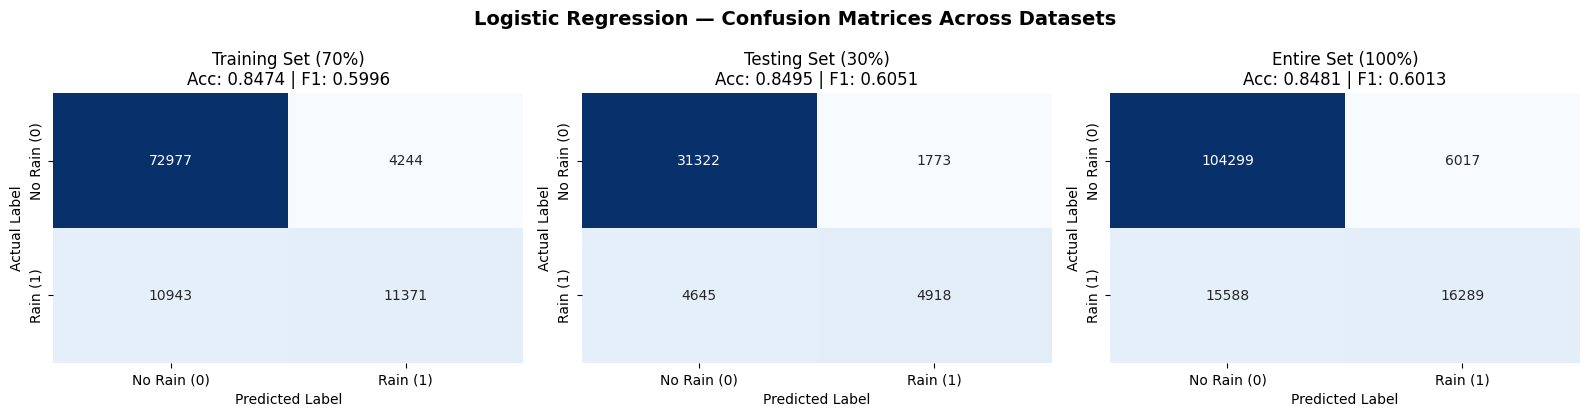

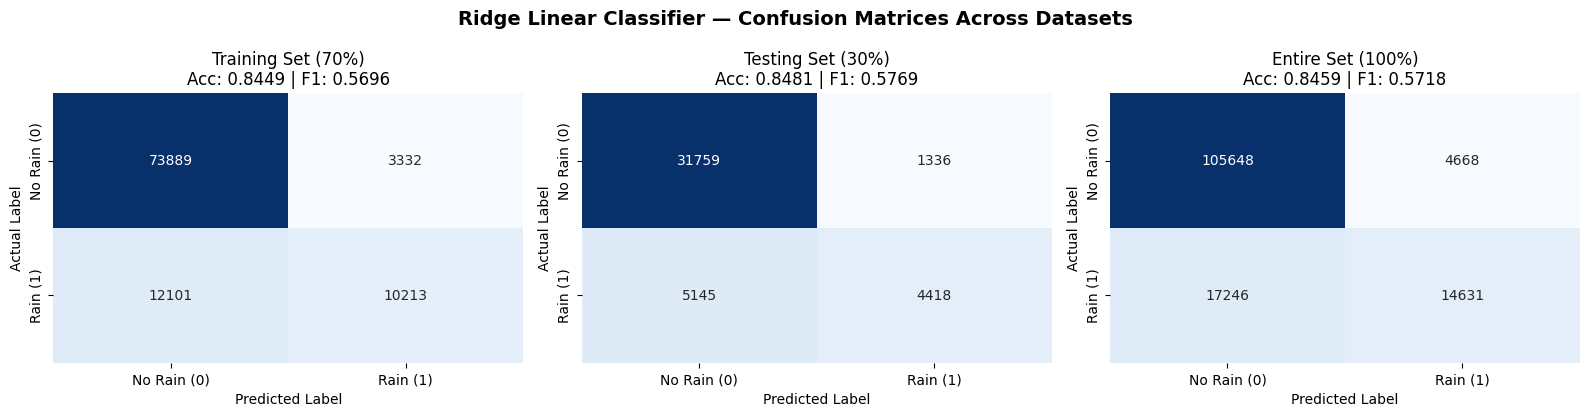

,Model,Dataset,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,Training Set (70%),0.8474,0.7282,0.5096,0.5996
1,Logistic Regression,Testing Set (30%),0.8495,0.7350,0.5143,0.6051
2,Logistic Regression,Entire Set (100%),0.8481,0.7303,0.5110,0.6013
3,Ridge Linear Classifier,Training Set (70%),0.8449,0.7540,0.4577,0.5696
4,Ridge Linear Classifier,Testing Set (30%),0.8481,0.7678,0.4620,0.5769
5,Ridge Linear Classifier,Entire Set (100%),0.8459,0.7581,0.4590,0.5718


In [15]:
# Define the 3 evaluation datasets required by Task 4 Deliverable 4
eval_datasets = {
    "Training Set (70%)": (X_train, y_train),
    "Testing Set (30%)": (X_test, y_test),
    "Entire Set (100%)": (X, y)
}

# Initialize linear models
linear_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Ridge Linear Classifier": RidgeClassifier(alpha=1.0, random_state=42)
}

partA_results = []

for model_name, model in linear_models.items():
    # Train strictly on the 70% training set
    model.fit(X_train, y_train)

    # Set up 1x3 subplots for confusion matrices
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
    fig.suptitle(f"{model_name} — Confusion Matrices Across Datasets", fontsize=14, fontweight="bold")

    for idx, (set_name, (X_eval, y_eval)) in enumerate(eval_datasets.items()):
        y_pred = model.predict(X_eval)

        # Compute performance metrics
        acc = accuracy_score(y_eval, y_pred)
        prec = precision_score(y_eval, y_pred, zero_division=0)
        rec = recall_score(y_eval, y_pred, zero_division=0)
        f1 = f1_score(y_eval, y_pred, zero_division=0)

        partA_results.append({
            "Model": model_name,
            "Dataset": set_name,
            "Accuracy": acc,
            "Precision": prec,
            "Recall": rec,
            "F1-Score": f1
        })

        # Plot confusion matrix
        cm = confusion_matrix(y_eval, y_pred)
        sns.heatmap(
            cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[idx],
            xticklabels=["No Rain (0)", "Rain (1)"],
            yticklabels=["No Rain (0)", "Rain (1)"]
        )
        axes[idx].set_title(f"{set_name}\nAcc: {acc:.4f} | F1: {f1:.4f}")
        axes[idx].set_xlabel("Predicted Label")
        axes[idx].set_ylabel("Actual Label")

    plt.tight_layout()
    plt.show()

# Display metrics table
partA_df = pd.DataFrame(partA_results)
display(partA_df.round(4))

In [16]:
## Section 3 — Visualization of Decision Boundaries (Deliverable 3)

## Since the preprocessed dataset has 115 dimensions, we project the decision boundary onto the 2D plane formed by the two continuous weather features most strongly correlated with `RainTomorrow`: **`Humidity3pm`** ($r = 0.440$) and **`Sunshine`** ($r = -0.324$).
## We compare the linear decision boundary of **Logistic Regression** against the non-linear, axis-aligned boundary of a **Decision Tree**.

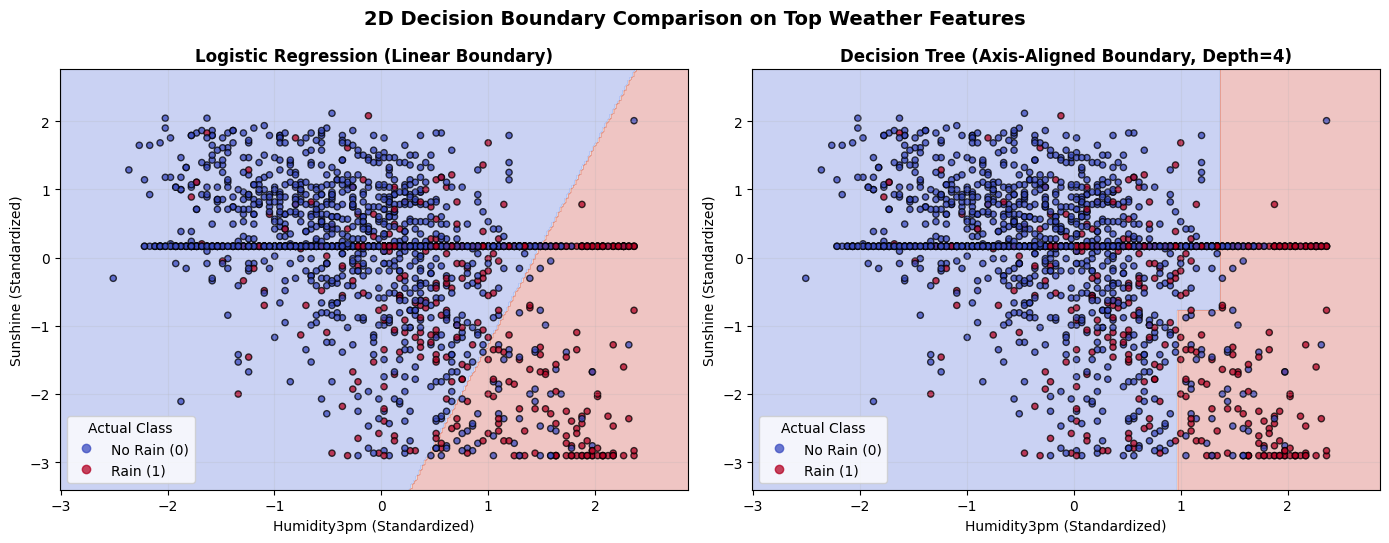

In [17]:
# Select top 2 correlated continuous features for 2D visualization
feat1, feat2 = "Humidity3pm", "Sunshine"
X_train_2d = X_train[[feat1, feat2]].values
y_train_2d = y_train.values

# Subsample 2,000 points for clear scatter visualization
np.random.seed(42)
sample_indices = np.random.choice(len(X_train_2d), size=2000, replace=False)
X_plot, y_plot = X_train_2d[sample_indices], y_train_2d[sample_indices]

# Create a dense 2D meshgrid
x_min, x_max = X_train_2d[:, 0].min() - 0.5, X_train_2d[:, 0].max() + 0.5
y_min, y_max = X_train_2d[:, 1].min() - 0.5, X_train_2d[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250),
                     np.linspace(y_min, y_max, 250))

boundary_classifiers = [
    ("Logistic Regression (Linear Boundary)", LogisticRegression(random_state=42)),
    ("Decision Tree (Axis-Aligned Boundary, Depth=4)", DecisionTreeClassifier(max_depth=4, random_state=42))
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for ax, (title, clf) in zip(axes, boundary_classifiers):
    clf.fit(X_train_2d, y_train_2d)
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    # Plot decision regions and data points
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    scatter = ax.scatter(
        X_plot[:, 0], X_plot[:, 1], c=y_plot, cmap="coolwarm",
        edgecolor="k", s=20, alpha=0.75
    )
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel(f"{feat1} (Standardized)")
    ax.set_ylabel(f"{feat2} (Standardized)")
    ax.legend(handles=scatter.legend_elements()[0], labels=["No Rain (0)", "Rain (1)"], title="Actual Class")
    ax.grid(alpha=0.2)

plt.suptitle("2D Decision Boundary Comparison on Top Weather Features", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# 新段落